## 0. BO vs CMA-ES: Data Analysis

File-driven analysis of the saved BO/CMA-ES experiment.

Structure:

1. Setup and loading
2. Sanity checks
3. Final performance vs ambient dimension
4. Best-so-far optimality gap vs evaluations
5. Alignment entropy analysis (final, fixed-evaluation, and slope views)

This notebook reads the saved problem/run files only. It does not rerun optimization.

The first load builds a processed cache under `DATA_DIR/cache/`. Later sessions load that cache directly unless the raw run-file set changes or `REBUILD_CACHE=True`.

Plotting helpers accept `save=True`. Saved figures are organized by figure type under `DATA_DIR/figures/`.

NOTICE: Need $n_\mathrm{rot} > 2$ for regression lines in plot 3 & 4.

## 1. Setup and data loading


In [1]:
from pathlib import Path
import json
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Change this to the folder containing problems/ and runs/.
DATA_DIR = Path("../data_long3")
PROBLEM_DIR = DATA_DIR / "problems"
RUN_DIR = DATA_DIR / "runs"

# Processed cache: avoids reopening thousands of raw JSON/NPZ files each session.
CACHE_DIR = DATA_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
CACHE_FILE = CACHE_DIR / "processed_records.pkl"
CACHE_MANIFEST = CACHE_DIR / "processed_records_manifest.json"

# Set True whenever you explicitly want to ignore/rebuild the cache.
REBUILD_CACHE = False

# Figure output.
FIGURE_DIR = DATA_DIR / "figures"
FIGURE_DPI = 200

# Global plot controls.
SAVE_PLOTS = False
SAVE_PLOT_1 = SAVE_PLOTS and True 
SAVE_PLOT_2 = SAVE_PLOTS and True
SAVE_PLOT_3 = SAVE_PLOTS and True
SAVE_PLOT_4 = SAVE_PLOTS and True

# Whether alignment-entropy analyses include the axis-aligned embedding (AAE).
INCLUDE_AAE = True

# Plot 3 and Plot 4 are generated for every available d.
# Choose which objectives to generate here.
PLOT_3_OBJECTIVES = ("norm", "branin")
PLOT_4_OBJECTIVES = ("norm", "branin")

GLOBAL_MIN = {
    "norm": 0.0,
    "branin": 0.39788735772973816,
}


In [2]:
def load_json_if_exists(path):
    path = Path(path)
    if not path.exists():
        return None
    with open(path, "r") as f:
        return json.load(f)


def load_problem_from_disk(problem_id, data_dir=DATA_DIR):
    root = Path(data_dir) / "problems"

    with np.load(root / f"{problem_id}.npz") as arr:
        A = np.asarray(arr["A"], dtype=float)
        X_init = np.asarray(arr["X_init"], dtype=float)
        y_init = np.asarray(arr["y_init"], dtype=float)

    with open(root / f"{problem_id}.json", "r") as f:
        meta = json.load(f)

    return {
        **meta,
        "A": A,
        "X_init": X_init,
        "y_init": y_init,
    }


def load_all_runs(data_dir=DATA_DIR):
    run_root = Path(data_dir) / "runs"
    records = []

    for meta_path in sorted(run_root.glob("*.json")):
        npz_path = meta_path.with_suffix(".npz")

        if not npz_path.exists():
            print(f"Warning: missing array file for {meta_path.name}; skipping")
            continue

        with open(meta_path, "r") as f:
            meta = json.load(f)

        with np.load(npz_path, allow_pickle=True) as arr:
            y_new = np.asarray(arr["y_new"], dtype=float)

        problem = load_problem_from_disk(meta["problem_id"], data_dir)

        A = problem["A"]
        y_init = problem["y_init"]

        y_all = np.concatenate([y_init, y_new])
        best_so_far = np.minimum.accumulate(y_all)

        f_min = GLOBAL_MIN[problem["objective_name"]]
        gap = np.maximum(best_so_far - f_min, 0.0)

        records.append({
            **meta,
            "objective_name": problem["objective_name"],
            "d": problem["d"],
            "k": problem["k"],
            "embedding": "aae" if problem["embedding"] == "inclusion" else problem["embedding"],
            "A_index": problem["A_index"],
            "init_index": problem["init_index"],
            "problem_seed": problem["problem_seed"],
            "A": A,
            "y_init": y_init,
            "y_new": y_new,
            "y_all": y_all,
            "best_so_far": best_so_far,
            "gap": gap,
            "final_best": float(best_so_far[-1]),
            "final_gap": float(gap[-1]),
            "n_evaluations": len(y_all),
        })

    return records


def make_summary(records):
    columns = [
        "run_id", "problem_id", "objective_name", "d", "k", "embedding",
        "A_index", "init_index", "solver", "solver_seed",
        "runtime_seconds", "n_evaluations", "final_best", "final_gap",
    ]
    return pd.DataFrame([
        {column: record.get(column) for column in columns}
        for record in records
    ])

def raw_run_signature(data_dir=DATA_DIR):
    """
    Lightweight signature of the current raw run set.
    If runs are added/removed/rewritten, the cache is rebuilt.
    """
    run_root = Path(data_dir) / "runs"
    files = sorted(list(run_root.glob("*.json")) + list(run_root.glob("*.npz")))
    return {
        "n_files": len(files),
        "total_size": int(sum(p.stat().st_size for p in files)),
        "latest_mtime_ns": int(max((p.stat().st_mtime_ns for p in files), default=0)),
    }


def load_records_cached(data_dir=DATA_DIR, rebuild=False):
    signature = raw_run_signature(data_dir)
    cached_signature = load_json_if_exists(CACHE_MANIFEST)

    cache_valid = (
        not rebuild
        and CACHE_FILE.exists()
        and cached_signature == signature
    )

    if cache_valid:
        print(f"Loading processed cache: {CACHE_FILE}")
        with open(CACHE_FILE, "rb") as f:
            return pickle.load(f)

    print("Building processed cache from raw run files...")
    records = load_all_runs(data_dir)

    with open(CACHE_FILE, "wb") as f:
        pickle.dump(records, f, protocol=pickle.HIGHEST_PROTOCOL)

    with open(CACHE_MANIFEST, "w") as f:
        json.dump(signature, f, indent=2)

    print(f"Saved processed cache: {CACHE_FILE}")
    return records


saved_config = load_json_if_exists(DATA_DIR / "config.json")
saved_versions = load_json_if_exists(DATA_DIR / "versions.json")

records = load_records_cached(DATA_DIR, rebuild=REBUILD_CACHE)

# Backward compatibility: old raw/cache files use embedding="inclusion".
# Analysis code uses "aae" = axis-aligned embedding.
for record in records:
    if record.get("embedding") == "inclusion":
        record["embedding"] = "aae"

summary = make_summary(records)

print("Data directory:", DATA_DIR.resolve())
print("Loaded completed runs:", len(records))
display(summary.head())


Loading processed cache: ..\data_long3\cache\processed_records.pkl
Data directory: C:\Users\CZ\Documents\GitHub\Bayesian-Optimisation-CMA-ES-project\data_long3
Loaded completed runs: 16800


,run_id,problem_id,objective_name,d,k,embedding,A_index,init_index,solver,solver_seed,runtime_seconds,n_evaluations,final_best,final_gap
0,branin_d10_inclusion_A0_init0__bo_ard,branin_d10_inclusion_A0_init0,branin,10,2,aae,0,0,bo_ard,3440624092,35.973510,150,0.399906,2.018982e-03
1,branin_d10_inclusion_A0_init0__bo_isotropic,branin_d10_inclusion_A0_init0,branin,10,2,aae,0,0,bo_isotropic,3839665796,15.087278,150,0.407417,9.529969e-03
2,branin_d10_inclusion_A0_init0__bo_oracle,branin_d10_inclusion_A0_init0,branin,10,2,aae,0,0,bo_oracle,1245201392,16.361091,150,0.397887,8.777478e-08
3,branin_d10_inclusion_A0_init0__cma_es,branin_d10_inclusion_A0_init0,branin,10,2,aae,0,0,cma_es,3061434033,0.072410,150,0.439353,4.146577e-02
4,branin_d10_inclusion_A0_init0__random,branin_d10_inclusion_A0_init0,branin,10,2,aae,0,0,random,1581657659,0.004041,150,2.212179,1.814292e+00


## 2. Sanity checks

These checks verify the integrity and structure of the saved experiment before interpreting any plots.

They check:

- what configuration and software versions were saved;
- which objectives, dimensions, embeddings and solvers are present;
- run counts for each experimental condition;
- evaluation-budget consistency;
- finite objective values;
- orthonormality of every saved $A$;
- consistency of a fixed $A$ across objectives and initialization sets;
- recorded runtime.


In [3]:
print("Problem JSON files:", len(list(PROBLEM_DIR.glob("*.json"))))
print("Run JSON files:", len(list(RUN_DIR.glob("*.json"))))

if saved_config is not None:
    print("\nSaved experiment config:")
    display(pd.Series(saved_config, name="value").to_frame())

if saved_versions is not None:
    print("\nSaved software versions:")
    display(pd.Series(saved_versions, name="version").to_frame())

if summary.empty:
    raise RuntimeError("No completed runs were loaded.")

print("\nDataset contents")
print("Objectives:", sorted(summary["objective_name"].unique()))
print("Dimensions:", sorted(summary["d"].unique()))
print("Embeddings:", sorted(summary["embedding"].unique()))
print("Solvers:", sorted(summary["solver"].unique()))
print("Initialization indices:", sorted(summary["init_index"].unique()))

completeness = (
    summary
    .groupby(["objective_name", "d", "embedding", "solver"])
    .size()
    .rename("completed_runs")
    .reset_index()
)
display(completeness)


Problem JSON files: 3360
Run JSON files: 16800

Saved experiment config:


,value
objectives,"[norm, branin]"
dimensions,"[2, 5, 10, 20]"
k,2
n_init_sets,20
n_rotations,20
budget,150
n_inclusion,1
n_init_pts,5
seed,42
domain,unit_ball



Saved software versions:


,version
python,3.12.16
numpy,2.5.4
scipy,1.18.1
pandas,3.1.0
sklearn,1.9.1
cma,4.0.0



Dataset contents
Objectives: ['branin', 'norm']
Dimensions: [np.int64(2), np.int64(5), np.int64(10), np.int64(20)]
Embeddings: ['aae', 'rotated']
Solvers: ['bo_ard', 'bo_isotropic', 'bo_oracle', 'cma_es', 'random']
Initialization indices: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19)]


,objective_name,d,embedding,solver,completed_runs
0,branin,2,aae,bo_ard,20
1,branin,2,aae,bo_isotropic,20
2,branin,2,aae,bo_oracle,20
3,branin,2,aae,cma_es,20
4,branin,2,aae,random,20
...,...,...,...,...,...
75,norm,20,rotated,bo_ard,400
76,norm,20,rotated,bo_isotropic,400
77,norm,20,rotated,bo_oracle,400
78,norm,20,rotated,cma_es,400


In [4]:
# Evaluation counts and finite-value checks

expected_budget = None
if saved_config is not None:
    expected_budget = saved_config.get("budget")

if expected_budget is not None:
    bad_budget = summary[summary["n_evaluations"] != expected_budget]
    print(f"Expected evaluations per run: {expected_budget}")
    print("Runs with wrong evaluation count:", len(bad_budget))
    if len(bad_budget):
        display(bad_budget)
else:
    print("No budget found in config.json; observed evaluation counts:")
    display(summary["n_evaluations"].value_counts().sort_index().rename("runs"))

nonfinite_runs = [
    r["run_id"]
    for r in records
    if not (
        np.all(np.isfinite(r["y_init"]))
        and np.all(np.isfinite(r["y_new"]))
    )
]

print("Runs containing non-finite objective values:", len(nonfinite_runs))
if nonfinite_runs:
    print(nonfinite_runs[:20])


Expected evaluations per run: 150
Runs with wrong evaluation count: 0
Runs containing non-finite objective values: 0


In [5]:
# Check saved A matrices.

orthogonality_errors = []
A_by_key = {}

for r in records:
    A = np.asarray(r["A"], dtype=float)
    k = A.shape[1]

    err = np.linalg.norm(A.T @ A - np.eye(k), ord="fro")
    orthogonality_errors.append(err)

    # A should depend on d, embedding and A_index, but not objective/init/solver.
    key = (r["d"], r["embedding"], r["A_index"])

    if key not in A_by_key:
        A_by_key[key] = A.copy()
    elif not np.allclose(A_by_key[key], A, atol=1e-12, rtol=0):
        raise AssertionError(f"Inconsistent A found for key {key}")

print("Unique A matrices:", len(A_by_key))
print("Maximum ||A.T A - I||_F:", max(orthogonality_errors))
print("A consistency across objectives/init sets/solvers: PASSED")


Unique A matrices: 84
Maximum ||A.T A - I||_F: 1.0648885158809838e-15
A consistency across objectives/init sets/solvers: PASSED


In [6]:
# Runtime summary

total_seconds = summary["runtime_seconds"].sum()

print(f"Total recorded runtime: {total_seconds / 3600:.2f} h")

runtime_by_solver = (
    summary.groupby("solver")["runtime_seconds"]
    .agg(["count", "sum", "mean", "median", "std"])
    .sort_values("sum", ascending=False)
)

runtime_by_solver["total_hours"] = runtime_by_solver["sum"] / 3600
display(runtime_by_solver)


Total recorded runtime: 97.96 h


,count,sum,mean,median,std,total_hours
solver,,,,,,
bo_ard,3360,223925.389269,66.644461,40.045914,57.267359,62.201497
bo_oracle,3360,68283.535246,20.322481,21.020763,6.267268,18.967649
bo_isotropic,3360,60163.364577,17.905763,16.745570,4.429903,16.712046
cma_es,3360,285.792773,0.085057,0.083071,0.015766,0.079387
random,3360,12.594663,0.003748,0.003465,0.001679,0.003499


### Alignment entropy distribution sanity check

This check reads the exact saved matrices $A$ directly from the `problems/` folder, deduplicates them by $(d,\,\mathrm{embedding},\,A\_\mathrm{index})$, and plots the distribution of alignment entropy for each ambient dimension.

The axis-aligned embedding is included and contributes one observation at $U(A)=0$ for each $d>k$. The case $d=k$ is omitted because the normalized entropy has denominator $\log(d/k)=0$.


,d,k,embedding,A_index,alignment_entropy
0,2,2,aae,0,NaN
1,2,2,rotated,0,NaN
2,2,2,rotated,1,NaN
3,2,2,rotated,2,NaN
4,2,2,rotated,3,NaN
...,...,...,...,...,...
79,20,2,rotated,15,0.806370
80,20,2,rotated,16,0.859038
81,20,2,rotated,17,0.883693
82,20,2,rotated,18,0.783581


Alignment entropy summary by dimension:


,n_A,mean,std,min,max
d,,,,,
5,21,0.707302,0.212689,0.0,0.933049
10,21,0.772026,0.185613,0.0,0.907955
20,21,0.801440,0.187325,0.0,0.892010


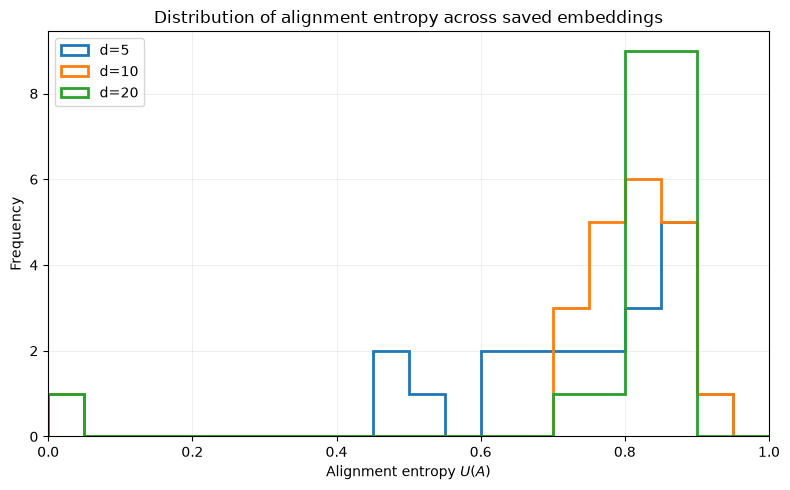

In [7]:
def alignment_entropy(A):
    A = np.asarray(A, dtype=float)
    d, k = A.shape

    # Normalization is undefined when d = k.
    if d == k:
        return np.nan

    # P = A A^T, so diag(P)_i = sum_j A_ij^2.
    diag_P = np.sum(A**2, axis=1)

    # trace(P) = k, hence p is a probability vector.
    p = diag_P / k
    p = p[p > 0]

    H = -np.sum(p * np.log(p))

    return float(
        (H - np.log(k))
        / (np.log(d) - np.log(k))
    )


def load_unique_problem_embeddings(problem_dir=PROBLEM_DIR):
    """
    Load one copy of every unique saved A directly from problems/.

    A is shared across objectives and init_index, so deduplicate using
    (d, embedding, A_index).
    """
    rows = []
    seen = set()

    for meta_path in sorted(Path(problem_dir).glob("*.json")):
        npz_path = meta_path.with_suffix(".npz")

        if not npz_path.exists():
            print(f"Warning: missing {npz_path.name}; skipping")
            continue

        with open(meta_path, "r") as f:
            meta = json.load(f)

        embedding = "aae" if meta["embedding"] == "inclusion" else meta["embedding"]

        key = (
            int(meta["d"]),
            embedding,
            int(meta["A_index"]),
        )

        if key in seen:
            continue

        seen.add(key)

        with np.load(npz_path) as arr:
            A = np.asarray(arr["A"], dtype=float)

        rows.append({
            "d": int(meta["d"]),
            "k": int(meta["k"]),
            "embedding": embedding,
            "A_index": int(meta["A_index"]),
            "alignment_entropy": alignment_entropy(A),
        })

    return (
        pd.DataFrame(rows)
        .sort_values(["d", "embedding", "A_index"])
        .reset_index(drop=True)
    )


problem_entropy_df = load_unique_problem_embeddings()

# Canonical entropy table used by the alignment-analysis sections below.
# One row per unique (d, embedding, A_index).
entropy_df = problem_entropy_df.copy()

# d = k has undefined normalized entropy and is excluded from the histogram.
entropy_plot_df = problem_entropy_df.dropna(
    subset=["alignment_entropy"]
).copy()

display(problem_entropy_df)

assert not entropy_df.empty
assert {"d", "embedding", "A_index", "alignment_entropy"}.issubset(entropy_df.columns)

entropy_summary = (
    entropy_plot_df
    .groupby("d")["alignment_entropy"]
    .agg(["count", "mean", "std", "min", "max"])
    .rename(columns={"count": "n_A"})
)

print("Alignment entropy summary by dimension:")
display(entropy_summary)


# Common bins make the distributions directly comparable across dimensions.
bins = np.linspace(0.0, 1.0, 21)

plt.figure(figsize=(8, 5))

for d, group in entropy_plot_df.groupby("d"):
    plt.hist(
        group["alignment_entropy"],
        bins=bins,
        histtype="step",
        linewidth=2,
        label=f"d={d}",
    )

plt.xlim(0.0, 1.0)
plt.xlabel("Alignment entropy $U(A)$")
plt.ylabel("Frequency")
plt.title("Distribution of alignment entropy across saved embeddings")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

SAVE_ENTROPY_HISTOGRAM = False
if SAVE_ENTROPY_HISTOGRAM:
    out_dir = FIGURE_DIR / "sanity_checks"
    out_dir.mkdir(parents=True, exist_ok=True)
    plt.savefig(
        out_dir / "alignment_entropy_distribution.png",
        dpi=FIGURE_DPI,
        bbox_inches="tight",
    )

plt.show()


## 3. Plot 1 — Final optimality gap vs ambient dimension

Given $(d, A, \text{solver})$, let

$$
G=f_{\mathrm{best}}-f^*.
$$

be the optimality gap averaged over $X_{\rm init}$

For each objective, embedding type, solver and dimension, the plot shows the mean final gap across all corresponding $A$ and initialization instances. Error bars are one standard error.

The y-axis is logarithmic.


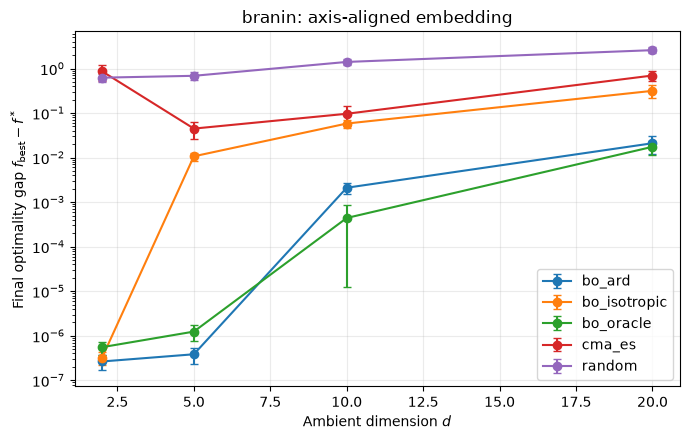

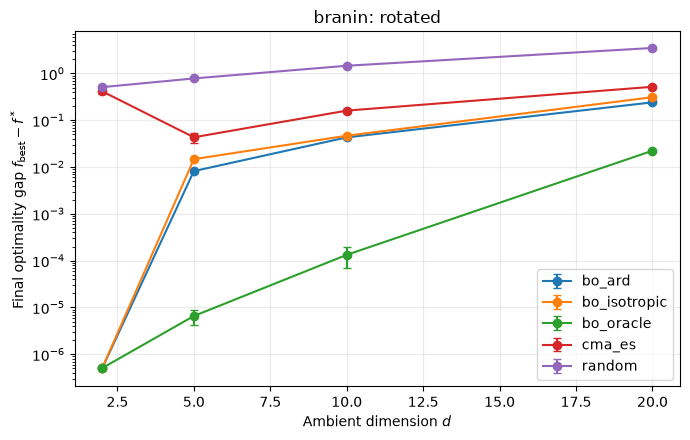

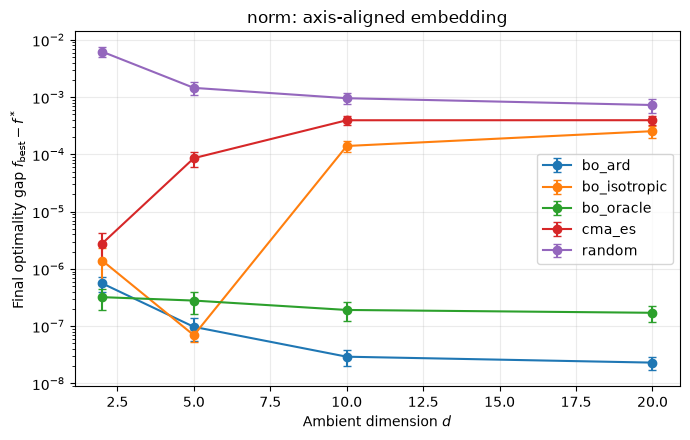

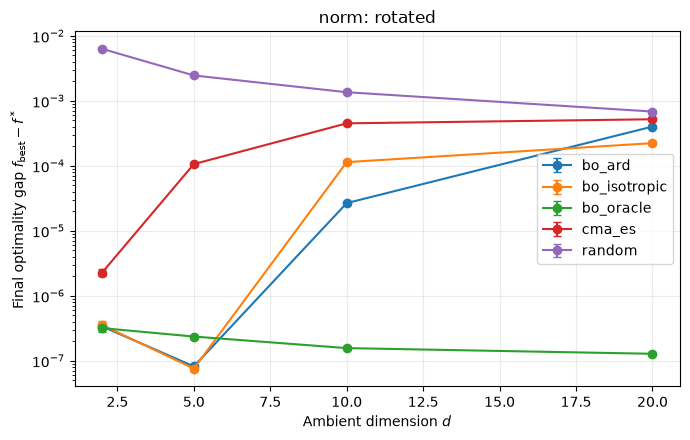

In [8]:
def plot_final_gap_vs_dimension(summary, save=False):
    if summary.empty:
        return

    for objective in sorted(summary["objective_name"].unique()):
        for embedding in sorted(summary["embedding"].unique()):
            sub = summary[
                (summary["objective_name"] == objective)
                & (summary["embedding"] == embedding)
            ].copy()

            if sub.empty:
                continue

            agg = (
                sub.groupby(["solver", "d"])["final_gap"]
                .agg(["mean", "std", "count"])
                .reset_index()
            )
            agg["se"] = agg["std"].fillna(0.0) / np.sqrt(agg["count"])

            plt.figure(figsize=(7, 4.5))

            for solver, group in agg.groupby("solver"):
                group = group.sort_values("d")

                plt.errorbar(
                    group["d"],
                    np.maximum(group["mean"], 1e-16),
                    yerr=group["se"],
                    marker="o",
                    capsize=3,
                    label=solver,
                )

            plt.yscale("log")
            plt.xlabel("Ambient dimension $d$")
            plt.ylabel(r"Final optimality gap $f_{\mathrm{best}} - f^*$")
            embedding_label = (
                "axis-aligned embedding" if embedding == "aae" else embedding
            )
            plt.title(f"{objective}: {embedding_label}")
            plt.legend()
            plt.grid(alpha=0.25)
            plt.tight_layout()

            if save:
                out_dir = FIGURE_DIR / "final_gap_vs_dimension"
                out_dir.mkdir(parents=True, exist_ok=True)
                filename = f"final_gap_vs_d__{objective}__{embedding}.png"
                plt.savefig(out_dir / filename, dpi=FIGURE_DPI, bbox_inches="tight")

            plt.show()


plot_final_gap_vs_dimension(summary, save=SAVE_PLOT_1)


## 4. Plot 2 — Best-so-far optimality gap vs evaluations

For each evaluation number $t$,

$$
G_t=f_{\mathrm{best},t}-f^*.
$$
where $f_{\mathrm{best},t}$ is the best-so-far evaluation up to $t$.

Curves are averaged over all runs belonging to the same objective, dimension, embedding and solver. The shaded region is mean $\pm$ one standard error.

The y-axis is logarithmic.


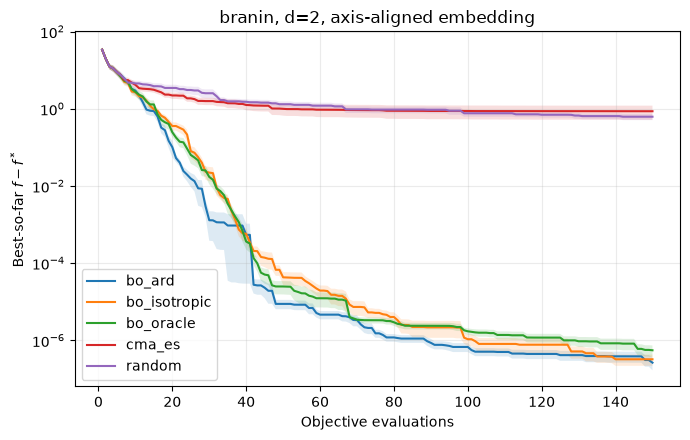

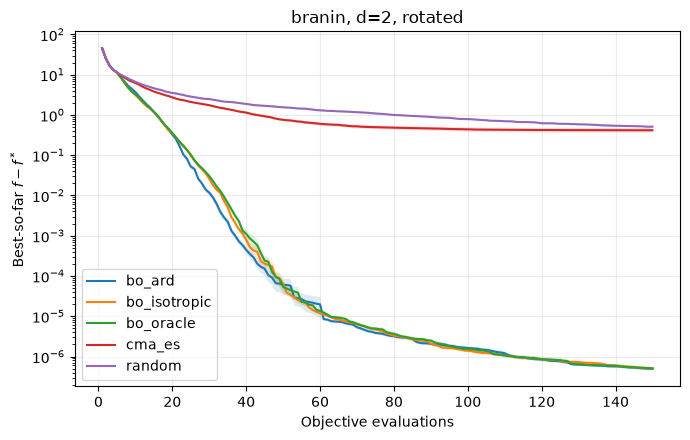

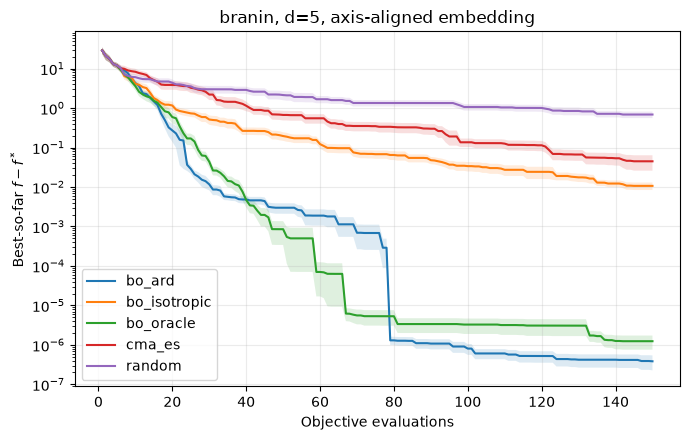

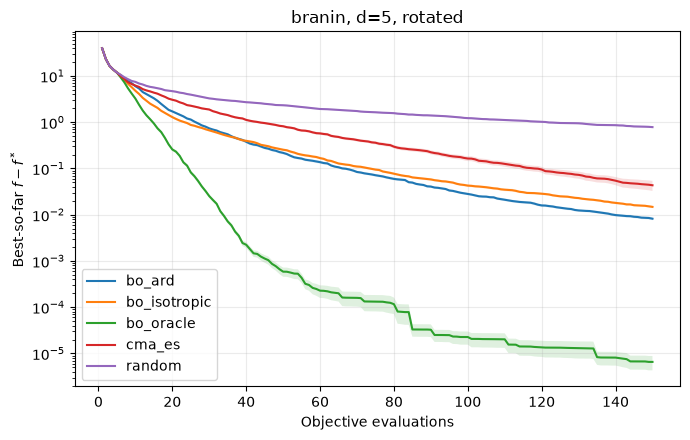

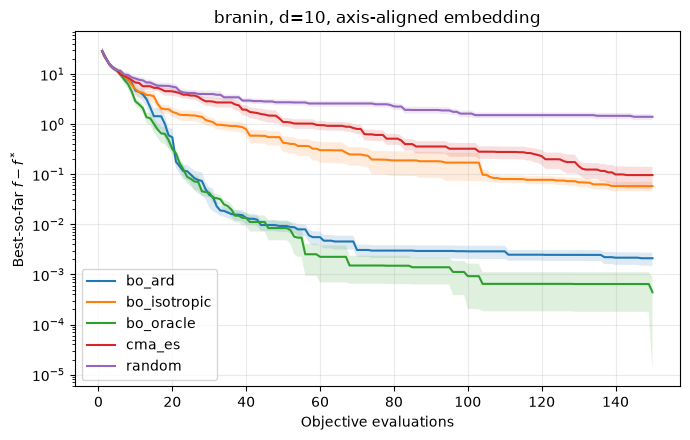

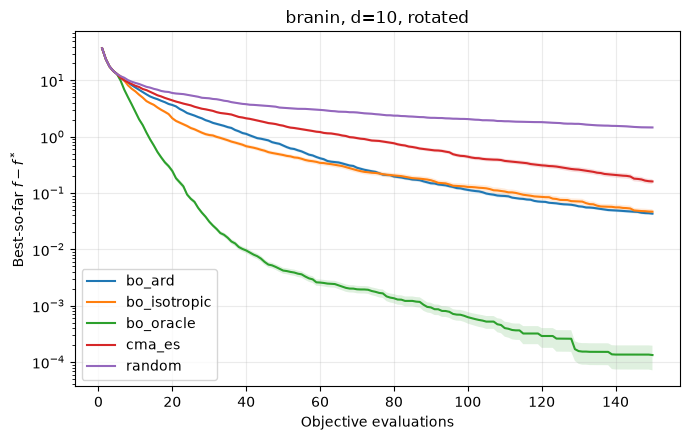

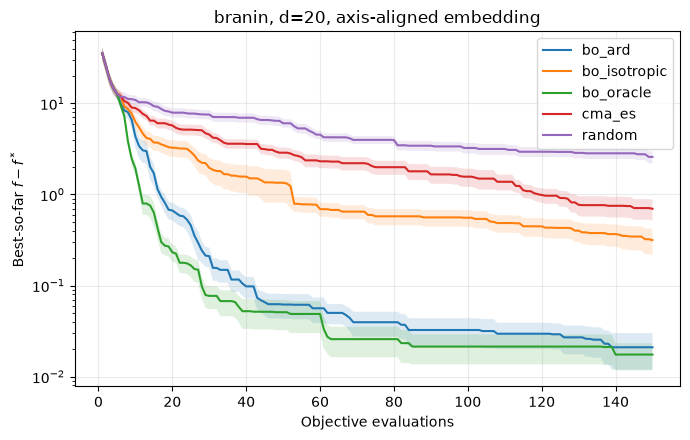

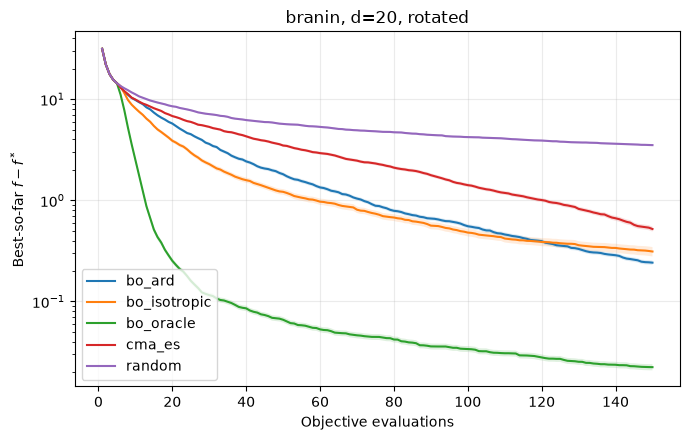

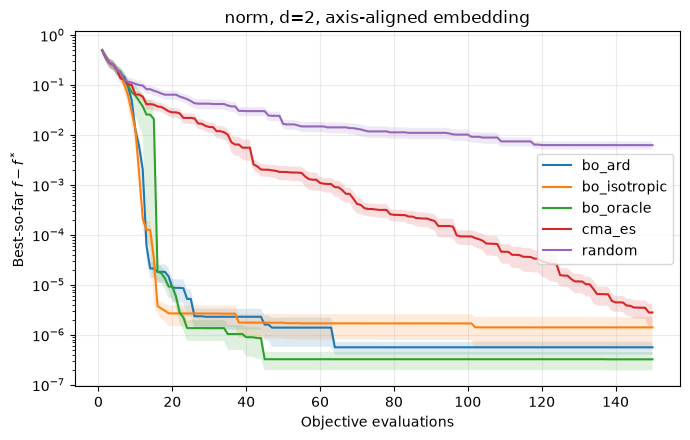

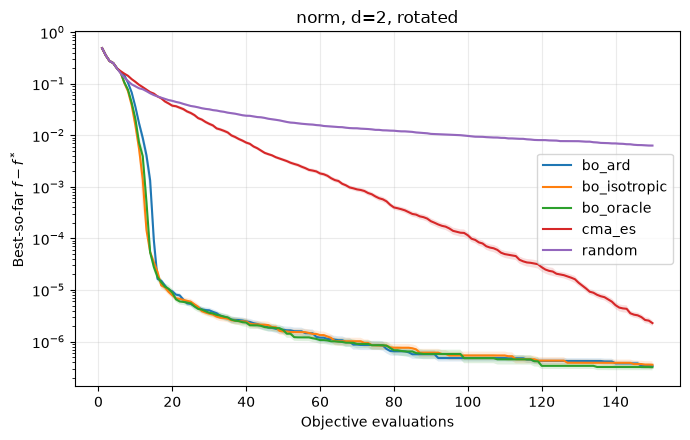

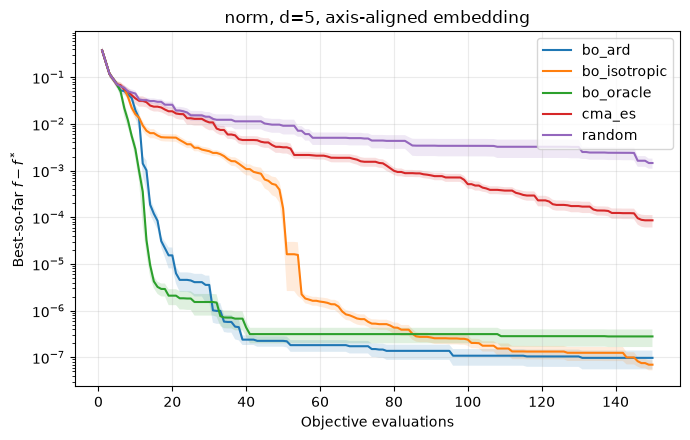

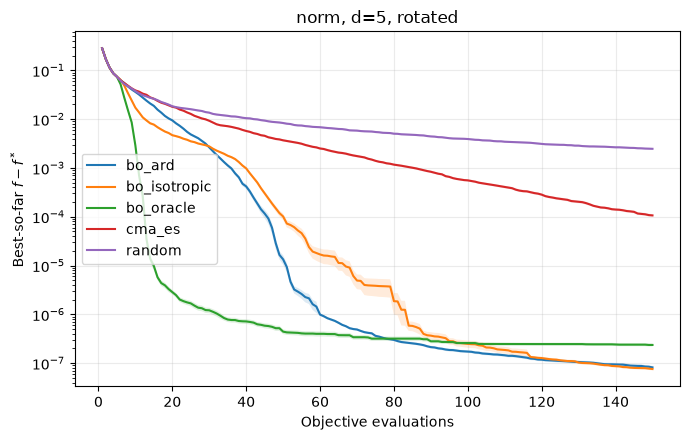

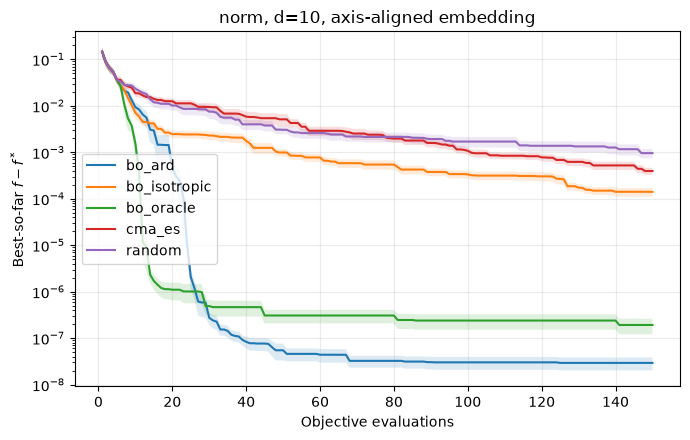

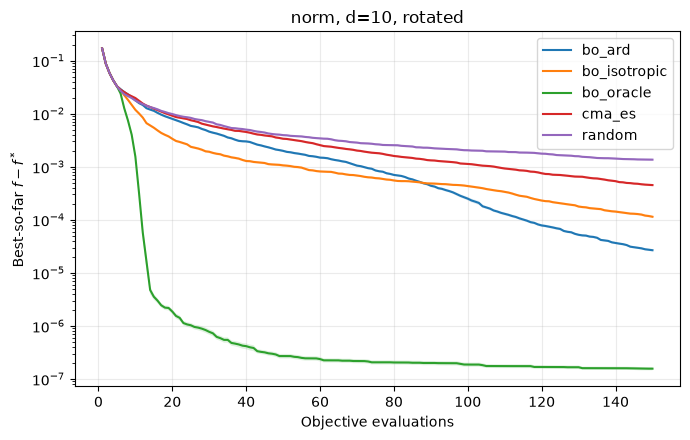

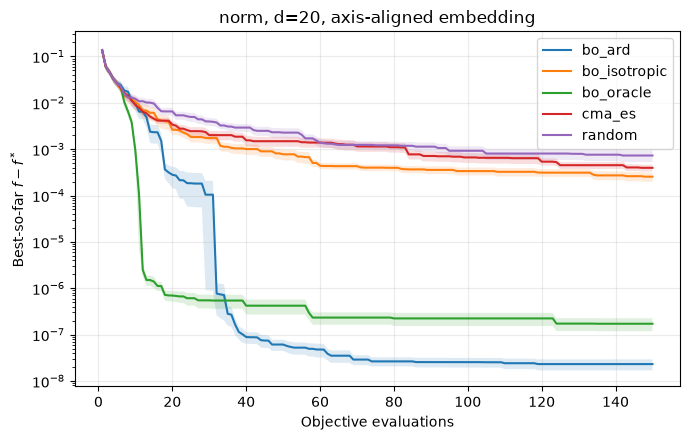

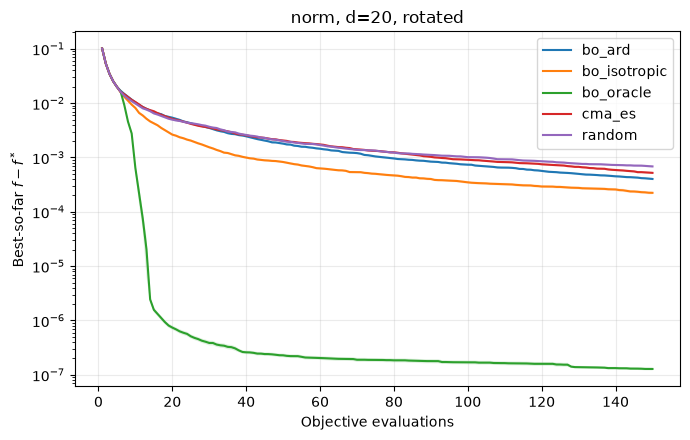

In [9]:
def plot_gap_vs_evaluations(records, save=False):
    if not records:
        return

    solvers = sorted({r["solver"] for r in records})

    keys = sorted({
        (r["objective_name"], r["d"], r["embedding"])
        for r in records
    })

    for objective, d, embedding in keys:
        subset = [
            r for r in records
            if r["objective_name"] == objective
            and r["d"] == d
            and r["embedding"] == embedding
        ]

        plt.figure(figsize=(7, 4.5))

        for solver in solvers:
            curves = [
                r["gap"]
                for r in subset
                if r["solver"] == solver
            ]

            if not curves:
                continue

            common_len = min(len(curve) for curve in curves)
            curves = np.vstack([
                curve[:common_len]
                for curve in curves
            ])

            mean = curves.mean(axis=0)

            if len(curves) > 1:
                se = curves.std(axis=0, ddof=1) / np.sqrt(len(curves))
            else:
                se = np.zeros_like(mean)

            x = np.arange(1, common_len + 1)

            plt.plot(
                x,
                np.maximum(mean, 1e-16),
                label=solver,
            )

            plt.fill_between(
                x,
                np.maximum(mean - se, 1e-16),
                np.maximum(mean + se, 1e-16),
                alpha=0.15,
            )

        plt.yscale("log")
        plt.xlabel("Objective evaluations")
        plt.ylabel(r"Best-so-far $f - f^*$")
        embedding_label = (
            "axis-aligned embedding" if embedding == "aae" else embedding
        )
        plt.title(f"{objective}, d={d}, {embedding_label}")
        plt.legend()
        plt.grid(alpha=0.25)
        plt.tight_layout()

        if save:
            out_dir = FIGURE_DIR / "gap_vs_evaluations"
            out_dir.mkdir(parents=True, exist_ok=True)
            filename = f"gap_vs_eval__{objective}__d{d}__{embedding}.png"
            plt.savefig(out_dir / filename, dpi=FIGURE_DPI, bbox_inches="tight")

        plt.show()


plot_gap_vs_evaluations(records, save=SAVE_PLOT_2)


## 5. Alignment entropy analysis

Alignment entropy $U(A)$ is a modified entropy metric that measures how spread the active subspace is across ambient coordinate axes. The axis-aligned embedding (AAE) has alignment entropy $U(A)=0$; larger entropy indicates less coordinate alignment.

For each fixed $A$ and solver, performance is first averaged over all available $X_{\rm init}$ sets. The global `INCLUDE_AAE` switch controls whether the AAE point is included in Plots 3 and 4 and in the Section 5.2 regression.

### 5.1 Plot 3 — Final performance vs alignment entropy

The performance metric is

$$
\mathrm{Perf}=-\log_{10}(G +\varepsilon),
$$

where $G$ is the final optimality gap averaged over $X_{\rm init}$. Plot 3 is generated for every available $d$ and each objective listed in `PLOT_3_OBJECTIVES`.


In [10]:
def filter_alignment_data(df, objective, d, include_aae=True):
    out = df[
        (df["objective_name"] == objective)
        & (df["d"] == d)
    ].copy()

    if not include_aae:
        out = out[out["embedding"] != "aae"].copy()

    return out.dropna(subset=["alignment_entropy", "performance"])


def build_alignment_performance_table(summary, entropy_df, epsilon=1e-12):
    perf = (
        summary
        .groupby(
            ["objective_name", "d", "embedding", "A_index", "solver"],
            as_index=False,
        )
        .agg(
            mean_final_gap=("final_gap", "mean"),
            n_init=("init_index", "nunique"),
        )
        .merge(
            entropy_df,
            on=["d", "embedding", "A_index"],
            how="left",
            validate="many_to_one",
        )
    )

    perf["performance"] = -np.log10(perf["mean_final_gap"] + epsilon)
    return perf


alignment_performance_df = build_alignment_performance_table(summary, entropy_df)


In [11]:
def plot_alignment_vs_performance(
    alignment_performance_df,
    objective,
    d,
    include_aae=True,
    save=False,
):
    df = filter_alignment_data(
        alignment_performance_df,
        objective,
        d,
        include_aae=include_aae,
    )

    if df.empty:
        raise ValueError(
            f"No alignment-performance data for objective={objective}, d={d}."
        )

    plt.figure(figsize=(8, 5))

    for solver, group in df.groupby("solver"):
        x = group["alignment_entropy"].to_numpy()
        y = group["performance"].to_numpy()

        scatter = plt.scatter(
            x,
            y,
            s=55,
            alpha=0.8,
            label=solver,
        )

        if len(x) >= 3 and np.ptp(x) > 0:
            reg = linregress(x, y)

            x_line = np.linspace(x.min(), x.max(), 100)
            y_line = reg.slope * x_line + reg.intercept

            plt.plot(
                x_line,
                y_line,
                color=scatter.get_facecolor()[0],
                linestyle="--",
                linewidth=2,
                label=f"{solver} fit ($R^2$={reg.rvalue**2:.2f})",
            )

    plt.xlabel("Alignment entropy $U(A)$")
    plt.ylabel(r"Performance $-\log_{10}(G+\epsilon)$")
    plt.title(
        f"Alignment entropy vs final solver performance\n"
        f"{objective}, d={d}, "
        f"axis-aligned embedding included={include_aae}"
    )
    plt.xlim(-0.03, 1.03)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()

    if save:
        out_dir = FIGURE_DIR / "alignment_entropy" / "final_performance"
        out_dir.mkdir(parents=True, exist_ok=True)
        aae_tag = "with_aae" if include_aae else "without_aae"
        filename = f"alignment_final__{objective}__d{d}__{aae_tag}.png"
        plt.savefig(out_dir / filename, dpi=FIGURE_DPI, bbox_inches="tight")

    plt.show()

    return df


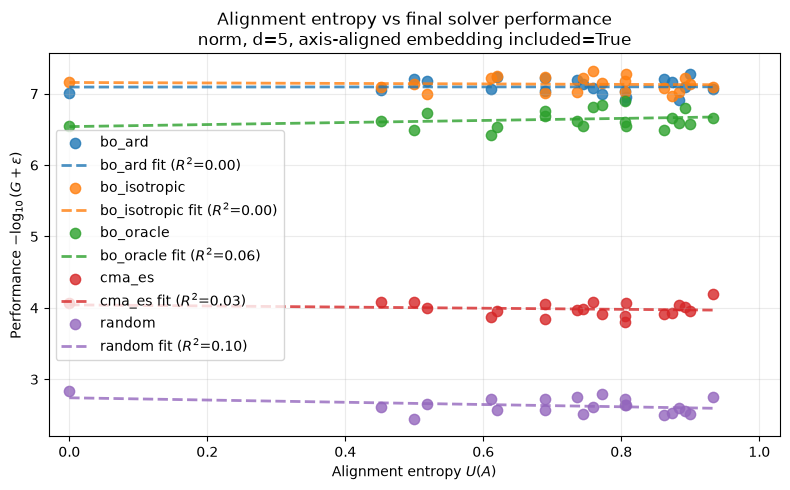

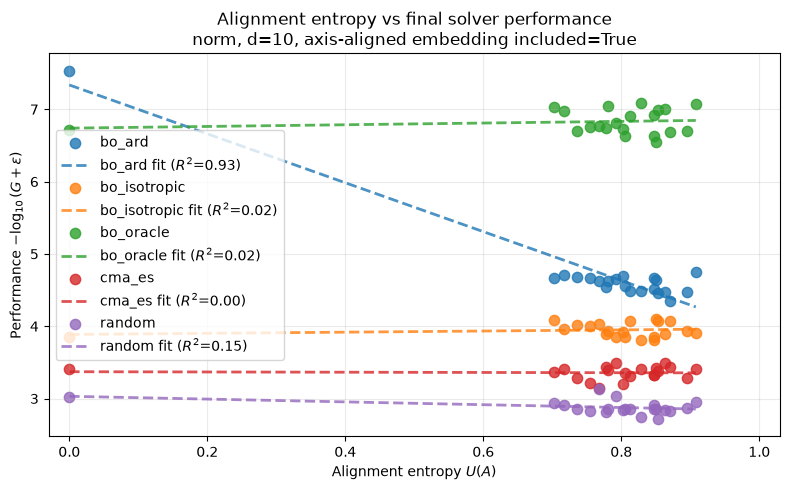

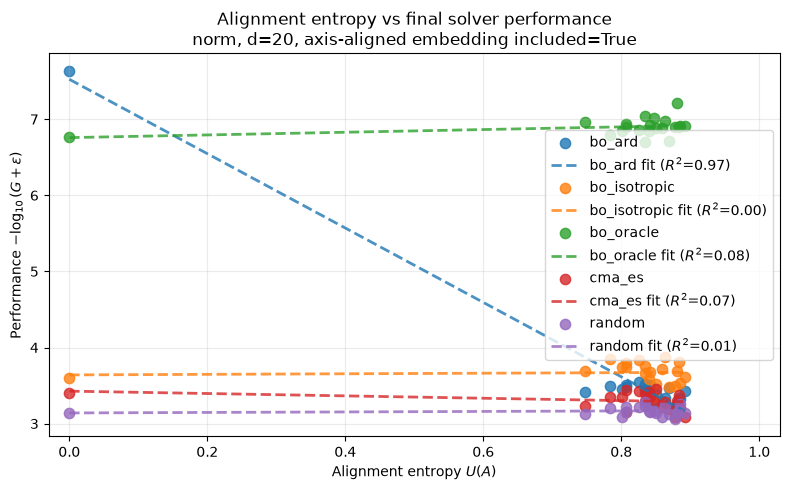

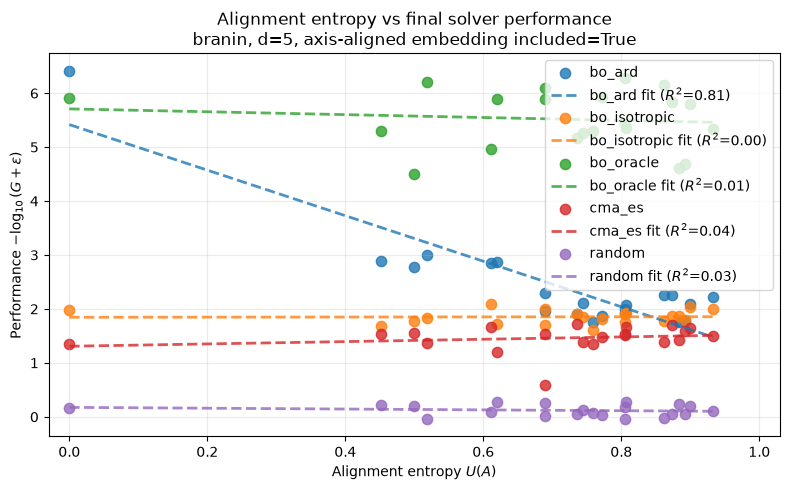

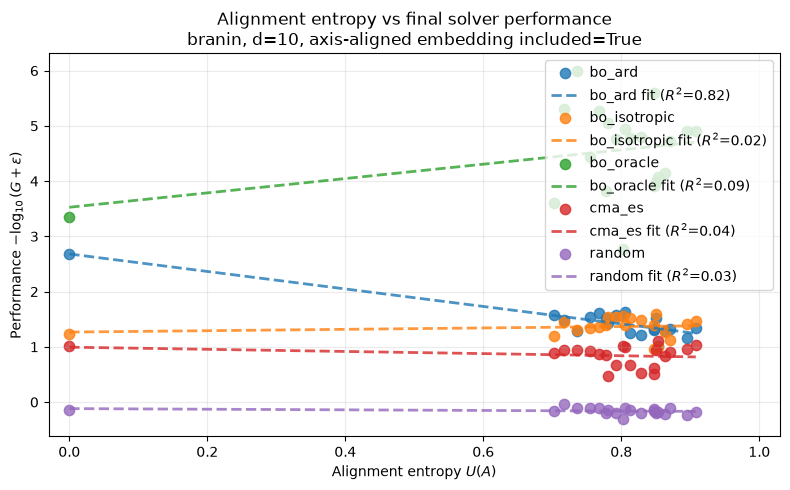

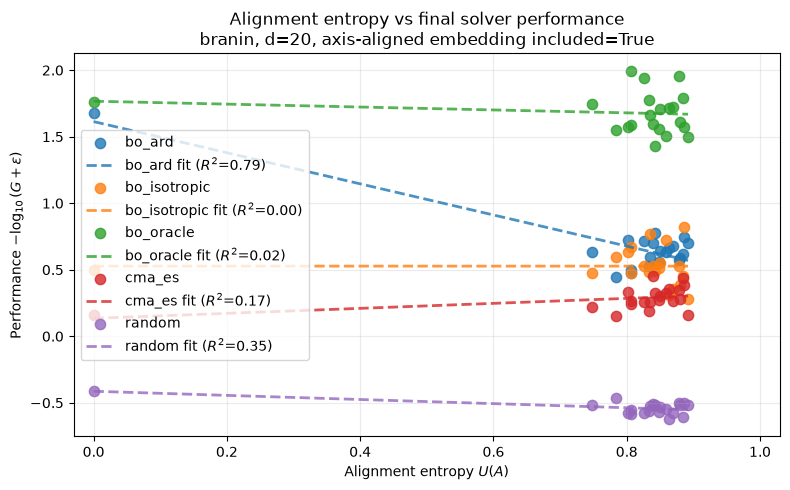

In [12]:
# Plot 3: final performance vs alignment entropy for every available d.
plot3_results = {}

for objective in PLOT_3_OBJECTIVES:
    for d in sorted(summary["d"].unique()):
        if d == 2: continue  # Skip d=2 because alignment entropy is undefined for d=k.
        key = (objective, int(d))
        plot3_results[key] = plot_alignment_vs_performance(
            alignment_performance_df,
            objective=objective,
            d=d,
            include_aae=INCLUDE_AAE,
            save=SAVE_PLOT_3,
        )


### 5.2 Performance at a fixed evaluation count

This is the same entropy-performance relationship at one chosen evaluation number $t$, rather than at the final budget. For each $A$ and solver,

$$
S_{s,t}(A)=-\log_{10}(\overline{G}_{s,t}(A)+\varepsilon).
$$

A separate linear regression is fitted for each solver. `INCLUDE_AAE` determines whether the axis-aligned embedding at $U(A)=0$ participates in both the scatter and regression. This diagnostic is called manually for a chosen objective, $d$, and evaluation count and is not saved automatically.


In [13]:
def build_alignment_performance_at_eval(records, entropy_df, evaluation, epsilon=1e-12):
    if evaluation < 1:
        raise ValueError("evaluation must be >= 1")

    rows = []
    for r in records:
        if evaluation > len(r["gap"]):
            continue

        rows.append({
            "objective_name": r["objective_name"],
            "d": r["d"],
            "embedding": r["embedding"],
            "A_index": r["A_index"],
            "init_index": r["init_index"],
            "solver": r["solver"],
            "gap_at_eval": float(r["gap"][evaluation - 1]),
        })

    if not rows:
        raise ValueError(f"No runs contain evaluation {evaluation}.")

    perf = (
        pd.DataFrame(rows)
        .groupby(
            ["objective_name", "d", "embedding", "A_index", "solver"],
            as_index=False,
        )
        .agg(
            mean_gap_at_eval=("gap_at_eval", "mean"),
            n_init=("init_index", "nunique"),
        )
        .merge(
            entropy_df,
            on=["d", "embedding", "A_index"],
            how="left",
            validate="many_to_one",
        )
    )

    perf["evaluation"] = int(evaluation)
    perf["performance"] = -np.log10(perf["mean_gap_at_eval"] + epsilon)
    return perf

Note: skip this if only `d=2` is available

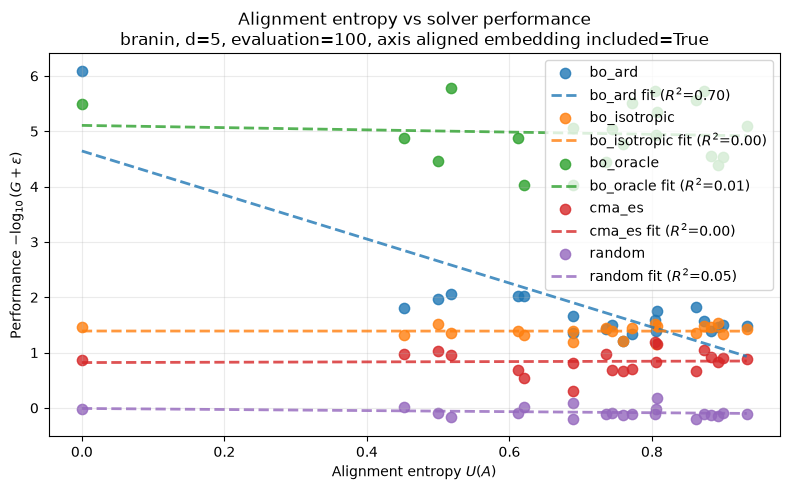

In [14]:
from scipy.stats import linregress


def plot_alignment_vs_performance_at_eval(
    records,
    entropy_df,
    objective,
    d,
    evaluation,
    include_aae=True,
    epsilon=1e-12,
):
    perf = build_alignment_performance_at_eval(
        records, entropy_df, evaluation, epsilon
    )
    df = filter_alignment_data(
        perf,
        objective,
        d,
        include_aae=include_aae,
    )

    if df.empty:
        raise ValueError(
            f"No data for objective={objective}, d={d}, evaluation={evaluation}."
        )

    plt.figure(figsize=(8, 5))
    regression_results = []

    for solver, group in df.groupby("solver"):
        x = group["alignment_entropy"].to_numpy()
        y = group["performance"].to_numpy()

        scatter = plt.scatter(x, y, s=55, alpha=0.8, label=solver)

        if len(x) >= 3 and np.ptp(x) > 0:
            result = linregress(x, y)
            x_line = np.linspace(x.min(), x.max(), 100)
            y_line = result.slope * x_line + result.intercept

            plt.plot(
                x_line,
                y_line,
                color=scatter.get_facecolor()[0],
                linewidth=2,
                linestyle="--",
                label=f"{solver} fit ($R^2$={result.rvalue**2:.2f})",
            )

            regression_results.append({
                "solver": solver,
                "slope": result.slope,
                "intercept": result.intercept,
                "r_squared": result.rvalue**2,
                "p_value": result.pvalue,
                "n": len(x),
                "include_aae": include_aae,
            })

    plt.xlabel("Alignment entropy $U(A)$")
    plt.ylabel(r"Performance $-\log_{10}(G+\epsilon)$")
    plt.title(
        f"Alignment entropy vs solver performance\n"
        f"{objective}, d={d}, evaluation={evaluation}, "
        f"axis aligned embedding included={include_aae}"
    )
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()


    plt.show()

    return df, regression_results


# Example
fixed_eval_df, fixed_eval_regression = plot_alignment_vs_performance_at_eval(
    records,
    entropy_df,
    objective="branin", # set to available objective in the dataset
    d=5, # set to available d in the dataset
    evaluation=100,
    include_aae=INCLUDE_AAE,
)


### 5.3 Plot 4 — Regression slope across evaluation number

At each evaluation number $t$, regress solver performance on alignment entropy:

$$
S_{s,t}(A)=\beta_{0,s,t}+\beta_{1,s,t}U(A)+\epsilon.
$$

Plot 4 shows the fitted slope $\beta_{1,s,t}$ against evaluation number. A negative slope means higher alignment entropy is associated with worse performance; a positive slope means the opposite. `INCLUDE_AAE` controls whether the axis-aligned embedding is included in each regression. Plot 4 is generated for every available $d$ and each objective listed in `PLOT_4_OBJECTIVES`.


In [15]:
def plot_alignment_slope_vs_eval(
    records,
    entropy_df,
    objective,
    d,
    evaluations=range(1, 151),
    include_aae=True,
    epsilon=1e-12,
    save=False,
):
    results = []

    for evaluation in evaluations:
        perf = build_alignment_performance_at_eval(
            records, entropy_df, evaluation, epsilon
        )
        df = filter_alignment_data(
            perf,
            objective,
            d,
            include_aae=include_aae,
        )

        for solver, group in df.groupby("solver"):
            x = group["alignment_entropy"].to_numpy()
            y = group["performance"].to_numpy()

            if len(x) < 3 or np.ptp(x) < 1e-12:
                continue

            reg = linregress(x, y)
            results.append({
                "evaluation": evaluation,
                "solver": solver,
                "slope": reg.slope,
                "intercept": reg.intercept,
                "r_squared": reg.rvalue**2,
                "p_value": reg.pvalue,
                "std_error": reg.stderr,
                "n": len(x),
                "include_aae": include_aae,
            })

    slopes_df = pd.DataFrame(results)
    if slopes_df.empty:
        print(
            f"No valid alignment regressions for "
            f"objective={objective}, d={d}, "
            f"include_aae={include_aae}."
        )
        return slopes_df

    plt.figure(figsize=(10, 6))
    for solver, group in slopes_df.groupby("solver"):
        group = group.sort_values("evaluation")
        plt.plot(
            group["evaluation"],
            group["slope"],
            linewidth=2,
            label=solver,
        )

    plt.axhline(0, color="black", linestyle="--", alpha=0.6)
    plt.xlabel("Number of objective evaluations")
    plt.ylabel("Regression slope of performance vs alignment entropy")
    plt.title(
        f"Effect of alignment entropy over optimization\n"
        f"{objective}, d={d}, axis aligned embedding included={include_aae}"
    )
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()

    if save:
        out_dir = FIGURE_DIR / "alignment_entropy" / "slope_vs_evaluation"
        out_dir.mkdir(parents=True, exist_ok=True)
        aae_tag = "with_aae" if include_aae else "without_aae"
        filename = f"alignment_slope__{objective}__d{d}__{aae_tag}.png"
        plt.savefig(out_dir / filename, dpi=FIGURE_DPI, bbox_inches="tight")

    plt.show()

    return slopes_df


# display(slopes_df.head(20))


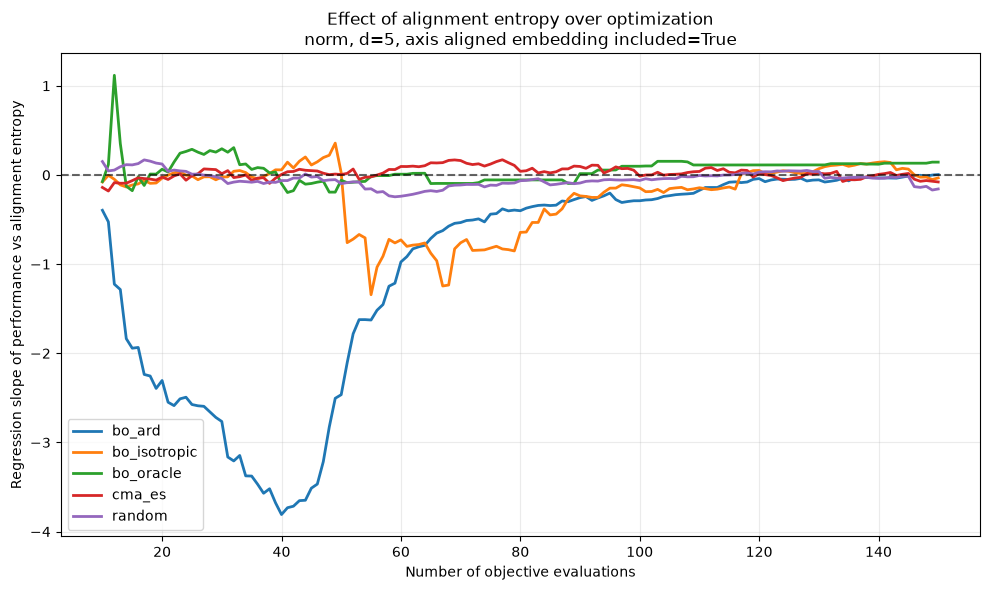

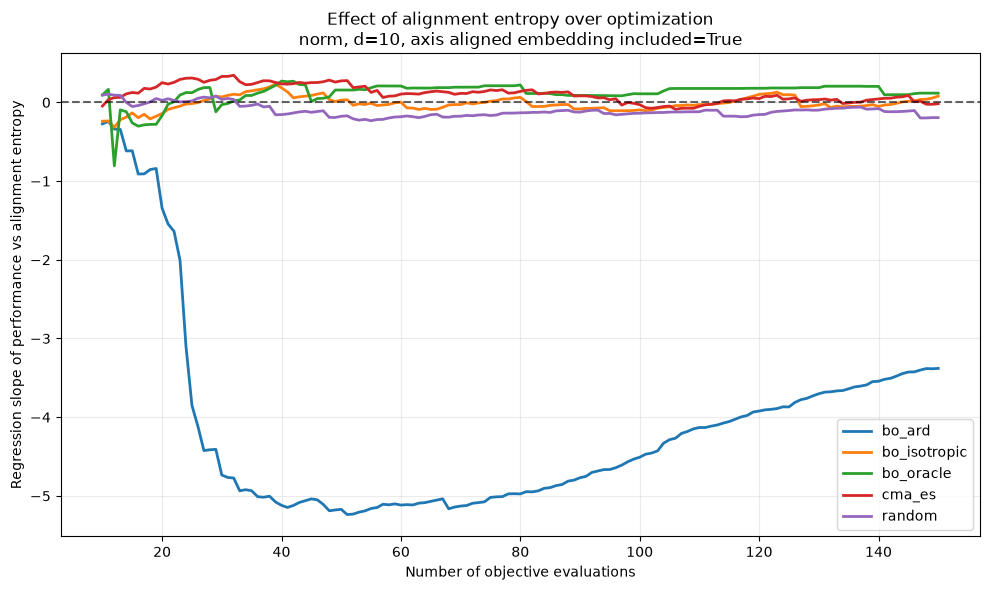

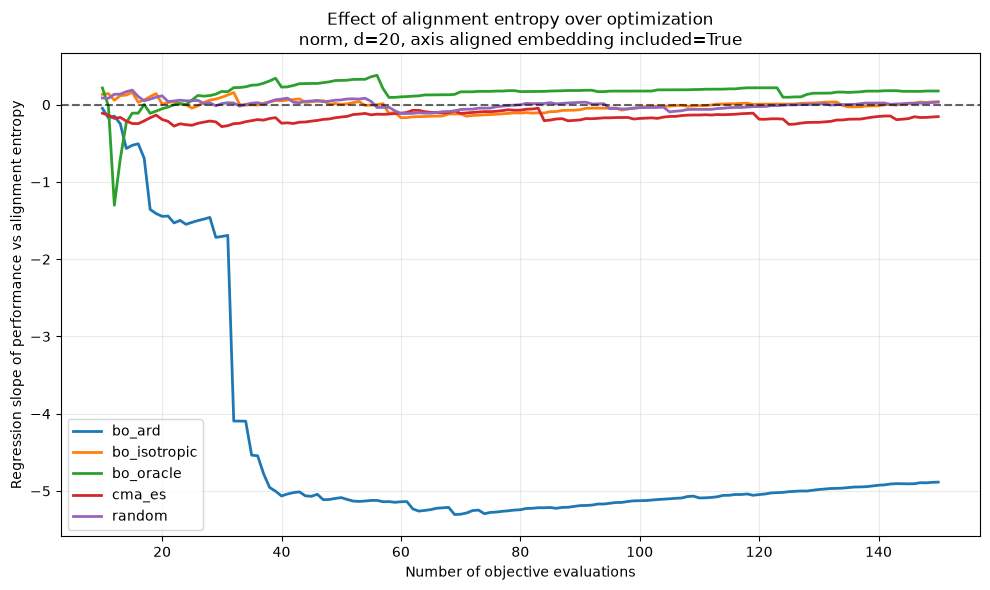

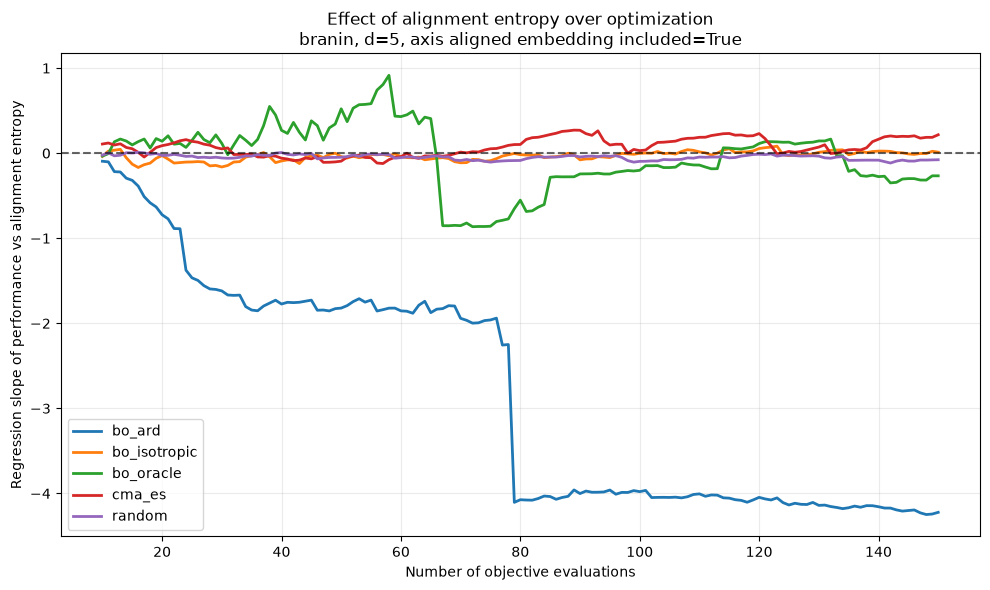

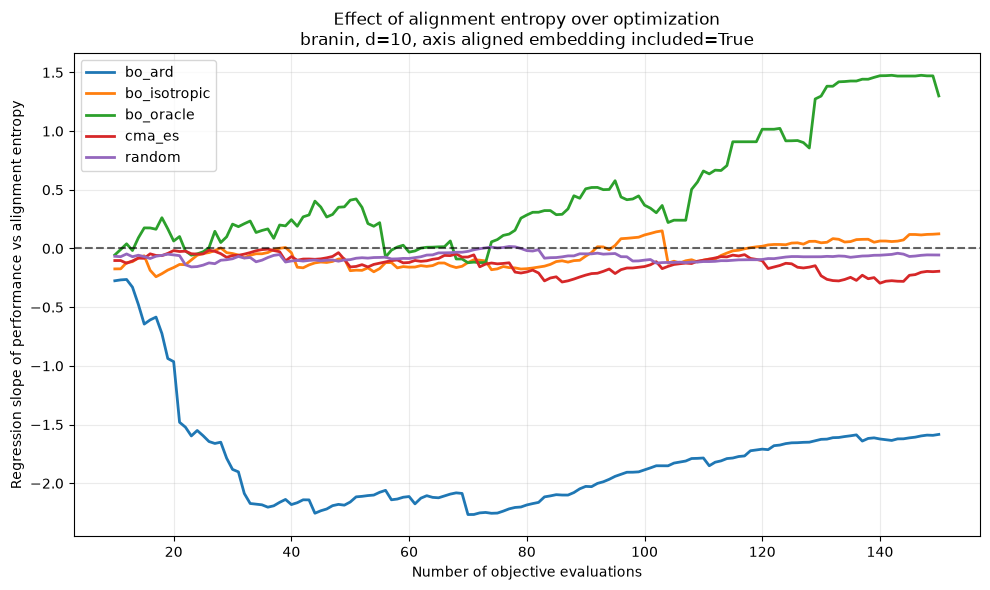

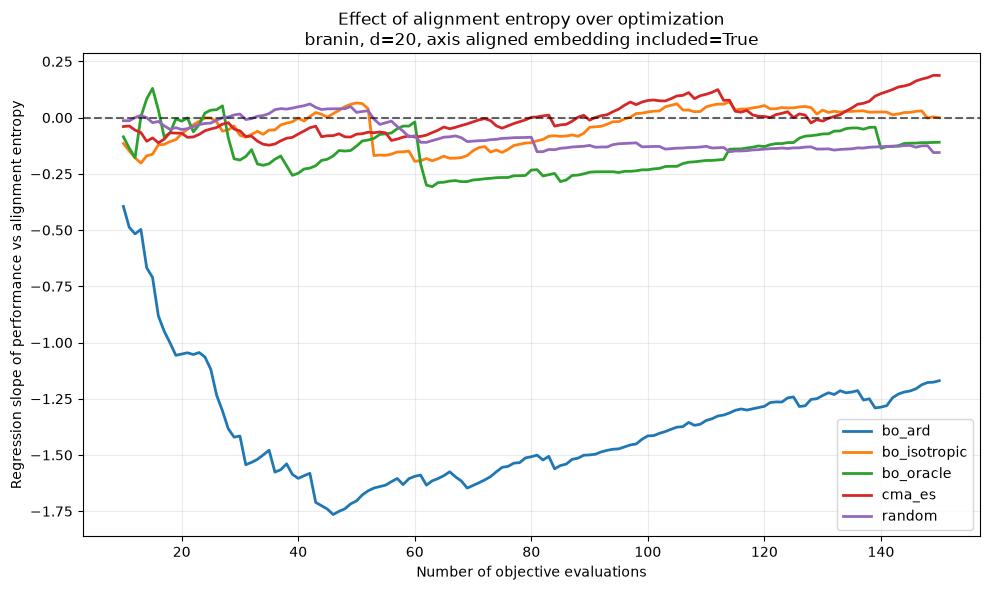

In [16]:
# Plot 4: regression slope over evaluations for every available d.
plot4_results = {}

for objective in PLOT_4_OBJECTIVES:
    for d in sorted(summary["d"].unique()):
        if d == 2: continue  # Skip d=2 because alignment entropy is undefined for d=k.
        key = (objective, int(d))
        plot4_results[key] = plot_alignment_slope_vs_eval(
            records,
            entropy_df,
            objective=objective,
            d=d,
            evaluations=range(10, 151),
            include_aae=INCLUDE_AAE,
            save=SAVE_PLOT_4,
        )


## 6.